# 02 · Validation and the vanilla RNN baseline
Point 2 of `PLAN.md` (owner: Ivan):
1. **Validation design:** which data we score on, and why it should track the public LB (2.1, 2.2).
2. **Baseline:** a 1-layer unidirectional vanilla RNN, word-level, random embeddings (2.3). Every other model is
   compared with it.
3. **First Kaggle submission**, with CV and LB in the results log (2.4).
4. **CV vs LB** over all submitted runs (2.5). The table grows as the team submits.

This notebook also holds the **master copy of section 0** (shared code).

**How to run:** on Colab with a T4, top to bottom, about 20 minutes. The last part submits to Kaggle once (1 of the
day's 10 submissions). Set the environment variable `QUICK_RUN=1` to check the code on a small subset, on CPU; that
never submits.

In [1]:
NOTEBOOK = "02-validation-baseline"  # W&B group of this notebook's runs

## 0. Shared code
Section 0 is **identical in every model notebook**, so all of them use the same splits, metric, tokenizer, training
loop and output format. The master copy is in notebook 02: change it there first, then paste it into the others.
Code specific to one notebook (a new model, a new tokenizer) goes in that notebook's own sections.

### 0.0 Setup
- **Colab:** upload `secrets.env` (`KAGGLE_USERNAME`, `KAGGLE_KEY`, `WANDB_API_KEY`) to `/content/` first. The cell
  loads the keys (it prints only their names), installs missing packages, and downloads the data with the Kaggle CLI.
  If Google Drive is mounted at `/content/drive`, run outputs go to `MyDrive/dl-a3-artifacts` so they survive the VM
  reset. Make that folder a shortcut to the team's shared folder, so everyone writes to the same results log.
- **Locally:** the data is read from `data/raw/`, outputs go to `artifacts/` (git-ignored).
- `QUICK_RUN=1` (environment variable) trains on a small subset for one epoch, to check the code in a few minutes.

In [2]:
import importlib.util
import os
import shutil
import subprocess
import sys
from pathlib import Path

COMPETITION = "kse-ua-location-extraction-2026"
DATA_FILES = ["uk_geo_dataset.csv", "labeling_sample.csv", "test.csv"]
IN_COLAB = Path("/content").exists()
QUICK_RUN = os.environ.get("QUICK_RUN") == "1"


def load_secrets(path: Path = Path("/content/secrets.env")) -> None:
    assert path.exists(), f"Upload secrets.env to {path.parent} first"
    for line in path.read_text().splitlines():
        if "=" in line and not line.lstrip().startswith("#"):
            key, value = line.split("=", 1)
            os.environ[key.strip()] = value.strip()
    print("keys loaded:", [k for k in ("KAGGLE_USERNAME", "KAGGLE_KEY", "WANDB_API_KEY") if os.environ.get(k)])


def download_data(raw: Path) -> None:
    raw.mkdir(parents=True, exist_ok=True)
    for name in DATA_FILES:
        if (raw / name).exists():
            continue
        subprocess.run(["kaggle", "competitions", "download", "-c", COMPETITION, "-f", name, "-p", str(raw)], check=True)
        archive = raw / f"{name}.zip"
        if archive.exists():  # large files arrive zipped
            shutil.unpack_archive(archive, raw)
            archive.unlink()


def install_missing(packages: dict[str, str]) -> None:
    """{import name: pip name}; installs only what is missing."""
    missing = [pip for module, pip in packages.items() if importlib.util.find_spec(module) is None]
    if missing:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)


install_missing({"lightning": "lightning", "tokenizers": "tokenizers", "wandb": "wandb", "kaggle": "kaggle"})
if IN_COLAB:
    load_secrets()
    RAW = Path("/content/data/raw")
    download_data(RAW)
    drive = Path("/content/drive/MyDrive")
    ARTIFACTS = (drive / "dl-a3-artifacts") if drive.exists() else Path("/content/artifacts")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    RAW, ARTIFACTS = ROOT / "data/raw", ROOT / "artifacts"
if QUICK_RUN:
    ARTIFACTS = ARTIFACTS / "quick_run"
ARTIFACTS.mkdir(parents=True, exist_ok=True)
print(f"data: {RAW} | outputs: {ARTIFACTS} | quick run: {QUICK_RUN}")

keys loaded: ['KAGGLE_USERNAME', 'KAGGLE_KEY', 'WANDB_API_KEY']
data: /content/data/raw | outputs: /content/artifacts | quick run: False


### 0.1 Tokenizer, span ↔ BIO, competition metric
Every training notebook uses the same code. Each token keeps its character offsets, so predicted tags can be turned
back into **exact substrings** of the text, which is what the metric compares. Punctuation becomes its own token
(`Київ,` → `Київ` `,`), while inner hyphens and apostrophes stay inside the word (`Івано-Франківськ`,
`Слов'янськ`).

In [3]:
import ast
import re
import string
from collections import Counter
from dataclasses import dataclass
from typing import List, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

TOKEN_RE = re.compile(r"\w+(?:[-'’ʼ`]\w+)*|[^\w\s]")


@dataclass(frozen=True)
class Token:
    text: str
    start: int
    end: int  # exclusive


def word_tokenize(text: str) -> list[Token]:
    return [Token(m.group(), m.start(), m.end()) for m in TOKEN_RE.finditer(text)]


def parse_markers(value) -> list[tuple[int, int]]:
    """`loc_markers` as stored in the CSV ("[(0, 4), (10, 15)]") -> [(start, end), ...], end exclusive."""
    if not isinstance(value, str):
        return []
    return [(int(a), int(b)) for a, b in ast.literal_eval(value.strip() or "[]")]


def spans_to_bio(tokens: Sequence[Token], spans) -> list[str]:
    """Every token that overlaps a span is labelled: the first one B-LOC, the rest I-LOC."""
    labels = ["O"] * len(tokens)
    for left, right in sorted(spans):
        first = True
        for i, tok in enumerate(tokens):
            if tok.start < right and tok.end > left:
                labels[i] = "B-LOC" if first else "I-LOC"
                first = False
    return labels


def bio_to_spans(tokens: Sequence[Token], tags: Sequence[str]) -> list[tuple[int, int]]:
    """Merge BIO tags into character spans; an I-LOC without an open entity starts a new one."""
    spans, current = [], None
    for tok, tag in zip(tokens, tags):
        if tag == "B-LOC" or (tag == "I-LOC" and current is None):
            if current is not None:
                spans.append(tuple(current))
            current = [tok.start, tok.end]
        elif tag == "I-LOC":
            current[1] = tok.end
        else:
            if current is not None:
                spans.append(tuple(current))
            current = None
    if current is not None:
        spans.append(tuple(current))
    return spans


def spans_to_strings(text: str, spans) -> list[str]:
    """Cut location strings out of the original text (deduplicated, order kept)."""
    return list(dict.fromkeys(s for s in (text[a:b].strip() for a, b in spans) if s))

`hard_processing` and `comp_metric` below are copied **verbatim** from the competition page. Do not "fix" them.

In [4]:
def hard_processing(text):
    text = re.sub(r"[{re.escape(string.punctuation)}]", "", text)
    text = re.sub(r'\d', '', text)
    text = re.sub(r'\b\w\b\s?', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.lower()


def comp_metric(y_true: List[List[str]], y_pred: List[List[str]]):
    assert len(y_true) == len(y_pred)
    tp, fp, fn, p,  = 0.0, 0.0, 0.0, 0.0

    for y_true_sample, y_pred_sample in zip(y_true, y_pred):
        y_true_sample = set([hard_processing(s) for s in y_true_sample])
        y_pred_sample = set([hard_processing(s) for s in y_pred_sample])

        tp += len(y_true_sample & y_pred_sample)
        fp += len(y_pred_sample - y_true_sample)
        fn += len(y_true_sample - y_pred_sample)
        p += len(y_true_sample)

    if tp + fp == 0:
        if p == 0:
            precision = 1.0
        else:
            precision = 0.0
    else:
        precision = tp/(tp + fp)

    if tp + fn == 0:
        if p == 0:
            recall = 1.0
        else:
            recall = 0.0
    else:
        recall = tp/(tp + fn)

    if precision + recall == 0:
        f1 = 0
    else:
        f1 = 2 * precision * recall / (precision + recall)
    return round(f1, 8)

Complementary metrics (notebook 01, section 8). They count exactly like `comp_metric`, plus:

In [5]:
def precision_recall(y_true, y_pred) -> tuple[float, float]:
    tp = fp = fn = 0
    for t_s, p_s in zip(y_true, y_pred):
        t, p = {hard_processing(s) for s in t_s}, {hard_processing(s) for s in p_s}
        tp, fp, fn = tp + len(t & p), fp + len(p - t), fn + len(t - p)
    precision = tp / (tp + fp) if tp + fp else float(tp + fn == 0)
    recall = tp / (tp + fn) if tp + fn else 1.0
    return precision, recall


def partial_match_f1(y_true, y_pred) -> float:
    """Boundary-tolerant F1: a location counts if it shares a normalized word with one on the other side."""
    words = lambda s: set(hard_processing(s).split())
    hit_p = n_p = hit_t = n_t = 0
    for t_s, p_s in zip(y_true, y_pred):
        t_sets = [words(s) for s in {hard_processing(x) for x in t_s}]
        p_sets = [words(s) for s in {hard_processing(x) for x in p_s}]
        n_p, n_t = n_p + len(p_sets), n_t + len(t_sets)
        hit_p += sum(any(p & t for t in t_sets) for p in p_sets)
        hit_t += sum(any(t & p for p in p_sets) for t in t_sets)
    precision, recall = (hit_p / n_p if n_p else 1.0), (hit_t / n_t if n_t else 1.0)
    return 2 * precision * recall / (precision + recall) if precision + recall else 0.0


def metric_report(y_true, y_pred) -> dict:
    precision, recall = precision_recall(y_true, y_pred)
    no_loc = [len(p) > 0 for t, p in zip(y_true, y_pred) if not t]
    with_loc = [(t, p) for t, p in zip(y_true, y_pred) if t]
    return {
        "comp_f1": comp_metric(y_true, y_pred),
        "precision": precision,
        "recall": recall,
        "partial_f1": partial_match_f1(y_true, y_pred),
        "f1_texts_with_loc": comp_metric([t for t, _ in with_loc], [p for _, p in with_loc]),
        "fp_rate_texts_without_loc": float(np.mean(no_loc)) if no_loc else 0.0,
    }


def bootstrap_ci(y_true, y_pred, n_boot: int = 2000, seed: int = 0, alpha: float = 0.05) -> tuple[float, float]:
    """95% interval of comp_metric when the texts are resampled with replacement (CV has only 26 texts)."""
    rng, n = np.random.default_rng(seed), len(y_true)
    scores = [comp_metric([y_true[i] for i in idx], [y_pred[i] for i in idx]) for idx in rng.integers(0, n, (n_boot, n))]
    low, high = np.quantile(scores, [alpha / 2, 1 - alpha / 2])
    return float(low), float(high)

### 0.2 Data: corpora and encoded datasets
- A `Corpus` holds the texts, word tokens and BIO tags (label ids) of one split, and the gold strings. For
  evaluation splits it also keeps the tokens with their offsets, which decoding needs (train skips them to save
  memory).
- A **vocabulary** maps words to ids. Any vocabulary works if it has
  `encode_batch(word_lists) -> [(ids, first_pos, last_pos), ...]`, where `first_pos[w]` and `last_pos[w]` are the
  positions of word `w`'s first and last id. For word-level they are equal. For BPE a word can have several pieces.
- `EncodedDataset` puts each word's label on its first or last piece (`alignment`). Every other position gets −100,
  which the loss ignores (same idea as `DataCollatorForTokenClassification` in the lecture). Training sequences are cut
  at `max_len` ids. Evaluation sequences are **never cut**, because test posts can be long (notebook 01).

In [6]:
import json
import logging
import time
import warnings
from collections import Counter

import lightning as L
import torch
import torch.nn as nn
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger, WandbLogger
from lightning.pytorch.utilities import grad_norm
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, Dataset

warnings.filterwarnings("ignore", module="lightning")
logging.getLogger("lightning.pytorch").setLevel(logging.WARNING)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
LABELS = ["O", "B-LOC", "I-LOC"]
LABEL2ID = {label: i for i, label in enumerate(LABELS)}
ID2LABEL = dict(enumerate(LABELS))
PAD_TOKEN, UNK_TOKEN, PAD_ID, UNK_ID, IGNORE_INDEX = "<pad>", "<unk>", 0, 1, -100
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")


class Corpus:
    def __init__(self, texts, spans=None, keep_tokens: bool = True):
        texts = [str(t) for t in texts]
        tokens = [word_tokenize(t) for t in texts]
        self.words = [[t.text for t in toks] for toks in tokens]
        self.tags = None if spans is None else [
            np.array([LABEL2ID[tag] for tag in spans_to_bio(toks, s)], dtype=np.int64) for toks, s in zip(tokens, spans)]
        self.gold = None if spans is None else [[t[a:b] for a, b in s] for t, s in zip(texts, spans)]
        self.texts, self.tokens = texts, (tokens if keep_tokens else None)

    def __len__(self) -> int:
        return len(self.words)


class WordVocab:
    """Word -> id, built on training words only; the `max_size` most frequent words seen `min_freq`+ times; the rest
    -> <unk>. `lowercase=False` keeps case (`Київ` and `київ` become different words)."""

    def __init__(self, word_lists, max_size: int = 50_000, min_freq: int = 2, lowercase: bool = True):
        self.norm = str.lower if lowercase else str
        counts = Counter(self.norm(w) for words in word_lists for w in words)
        self.itos = [PAD_TOKEN, UNK_TOKEN] + [w for w, c in counts.most_common(max_size - 2) if c >= min_freq]
        self.stoi = {w: i for i, w in enumerate(self.itos)}

    def __len__(self) -> int:
        return len(self.itos)

    def encode_batch(self, word_lists):
        for words in word_lists:
            ids = [self.stoi.get(self.norm(w), UNK_ID) for w in words]
            positions = list(range(len(words)))
            yield ids, positions, positions


class EncodedDataset(Dataset):
    def __init__(self, corpus: Corpus, vocab, alignment: str = "first", max_len: int | None = None):
        assert alignment in ("first", "last")
        self.items = []
        for i, (ids, first, last) in enumerate(vocab.encode_batch(corpus.words)):
            ids, pos = np.asarray(ids, dtype=np.int64), np.asarray(first if alignment == "first" else last, dtype=np.int64)
            labels = np.full(len(ids), IGNORE_INDEX, dtype=np.int64)
            if corpus.tags is not None:
                labels[pos] = corpus.tags[i]
            if max_len is not None and len(ids) > max_len:
                ids, labels, pos = ids[:max_len], labels[:max_len], pos[pos < max_len]
            self.items.append((ids, labels, pos))

    def __len__(self) -> int:
        return len(self.items)

    def __getitem__(self, idx: int):
        return (idx, *self.items[idx])


def collate(batch) -> dict:
    """Right-pad ids with PAD_ID and labels with −100; `lengths` feed pack_padded_sequence."""
    lengths = torch.tensor([max(len(ids), 1) for _, ids, _, _ in batch])
    input_ids = torch.full((len(batch), int(lengths.max())), PAD_ID, dtype=torch.long)
    labels = torch.full_like(input_ids, IGNORE_INDEX)
    for row, (_, ids, lab, _) in enumerate(batch):
        input_ids[row, :len(ids)] = torch.from_numpy(ids)
        labels[row, :len(lab)] = torch.from_numpy(lab)
    return {"idx": [b[0] for b in batch], "input_ids": input_ids, "labels": labels, "lengths": lengths,
            "positions": [b[3] for b in batch]}

device: cuda Tesla T4


**Splits** (point 2.1, motivated in notebook 02). They are fixed by the data, so they need no seed:
- **train** = `uk_geo_dataset` with `is_valid==0` (1M sentences);
- **es** = `is_valid==1` (10k sentences, train domain): early stopping and checkpoint choice;
- **CV** = `labeling_sample` (26 test-like texts): the score we report and compare with the LB;
- **test** = 477 posts for the submission.

`QUICK_RUN` samples 20k train and 2k es sentences with a fixed seed.

In [7]:
def load_corpora() -> tuple[dict[str, Corpus], pd.DataFrame]:
    uk = pd.read_csv(RAW / "uk_geo_dataset.csv", usecols=["text", "loc_markers", "is_valid"])
    ls = pd.read_csv(RAW / "labeling_sample.csv")
    test = pd.read_csv(RAW / "test.csv")
    train_df, es_df = uk[uk.is_valid == 0], uk[uk.is_valid == 1]
    if QUICK_RUN:
        train_df, es_df = train_df.sample(20_000, random_state=0), es_df.sample(2_000, random_state=0)
    corpora = {
        "train": Corpus(train_df.text, train_df.loc_markers.map(parse_markers), keep_tokens=False),
        "es": Corpus(es_df.text, es_df.loc_markers.map(parse_markers)),
        "cv": Corpus(ls.text, ls.loc_markers.map(parse_markers)),
        "test": Corpus(test.text),
    }
    return corpora, test

### 0.3 Model
Embedding → GRU / LSTM / RNN (optionally bidirectional, several layers) → a linear layer on every position.
`pack_padded_sequence` makes the RNN stop at each text's real length, so padding never enters the hidden state, not
even in the backward direction.

In [8]:
RNN_TYPES = {"rnn": nn.RNN, "gru": nn.GRU, "lstm": nn.LSTM}


class RNNTagger(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int = 128, hidden_dim: int = 256, rnn_type: str = "gru",
                 num_layers: int = 1, bidirectional: bool = True, dropout: float = 0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_ID)
        self.dropout = nn.Dropout(dropout)
        self.rnn = RNN_TYPES[rnn_type](embed_dim, hidden_dim, num_layers=num_layers, batch_first=True,
                                       bidirectional=bidirectional, dropout=dropout if num_layers > 1 else 0.0)
        self.classifier = nn.Linear(hidden_dim * (2 if bidirectional else 1), len(LABELS))

    def forward(self, input_ids: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        x = self.dropout(self.embedding(input_ids))
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.rnn(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=input_ids.size(1))
        return self.classifier(self.dropout(out))  # [batch, time, labels]

### 0.4 Training and decoding
- Loss: token-level cross-entropy, ignoring −100.
- After every epoch, both validation sets are decoded to strings and scored with the **competition metric**:
  - `es_f1` (train domain) selects the checkpoint and drives early stopping;
  - `cv_f1` (test-like) is only reported. Choosing epochs on 26 CV texts would overfit them.
- Gradient norms per parameter (before clipping) are logged every `log_every_n_steps` steps: the gradient-flow
  check.
- Decoding: word-level probabilities → argmax tag per word → BIO → character spans → strings cut from the text.

In [9]:
def word_probs(logits: torch.Tensor, positions) -> list[np.ndarray]:
    """[batch, time, labels] logits -> per text a [n_words, labels] probability array, read at the aligned piece."""
    probs = logits.float().softmax(-1).detach().cpu().numpy()
    return [probs[row, pos] for row, pos in enumerate(positions)]


def decode(corpus: Corpus, probs: list[np.ndarray]) -> list[list[str]]:
    tags = [[ID2LABEL[int(i)] for i in p.argmax(-1)] for p in probs]
    return [spans_to_strings(text, bio_to_spans(toks, t)) for text, toks, t in zip(corpus.texts, corpus.tokens, tags)]


class TaggerModule(L.LightningModule):
    def __init__(self, model: nn.Module, lr: float, weight_decay: float, val_corpora: dict[str, Corpus]):
        super().__init__()
        self.model, self.lr, self.weight_decay = model, lr, weight_decay
        self.val_names, self.val_corpora = list(val_corpora), list(val_corpora.values())
        self.loss_fn = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)

    def _loss(self, logits, labels):
        return self.loss_fn(logits.reshape(-1, logits.size(-1)), labels.reshape(-1))

    def training_step(self, batch, batch_idx):
        loss = self._loss(self.model(batch["input_ids"], batch["lengths"]), batch["labels"])
        self.log("train_loss", loss, on_step=True, on_epoch=True, batch_size=len(batch["idx"]))
        return loss

    def on_validation_epoch_start(self):
        self.val_probs = [{} for _ in self.val_names]

    def validation_step(self, batch, batch_idx, dataloader_idx=0):
        logits = self.model(batch["input_ids"], batch["lengths"])
        name = self.val_names[dataloader_idx]
        self.log(f"{name}_loss", self._loss(logits, batch["labels"]), batch_size=len(batch["idx"]),
                 add_dataloader_idx=False)
        self.val_probs[dataloader_idx].update(zip(batch["idx"], word_probs(logits, batch["positions"])))

    def on_validation_epoch_end(self):
        for name, corpus, buf in zip(self.val_names, self.val_corpora, self.val_probs):
            pred = decode(corpus, [buf[i] for i in range(len(corpus))])
            precision, recall = precision_recall(corpus.gold, pred)
            self.log_dict({f"{name}_f1": comp_metric(corpus.gold, pred), f"{name}_precision": precision,
                           f"{name}_recall": recall})

    def on_before_optimizer_step(self, optimizer):  # before clipping; Lightning writes it every log_every_n_steps
        self.log_dict(grad_norm(self.model, norm_type=2))

    def configure_optimizers(self):
        return torch.optim.AdamW(self.model.parameters(), lr=self.lr, weight_decay=self.weight_decay)


@torch.no_grad()
def predict(model: nn.Module, dataset: EncodedDataset, batch_size: int = 256) -> list[np.ndarray]:
    model.eval().to(DEVICE)
    out = [None] * len(dataset)
    for batch in DataLoader(dataset, batch_size=batch_size, collate_fn=collate):
        logits = model(batch["input_ids"].to(DEVICE), batch["lengths"])
        for i, p in zip(batch["idx"], word_probs(logits, batch["positions"])):
            out[i] = p
    return out

### 0.5 One experiment
`run_experiment(cfg, vocab, corpora, test_ids)`: train → reload the best checkpoint (by `es_f1`) → predict CV and test →
CV report → save outputs. If the run's `report.json` already exists it is loaded instead, so a crashed or
disconnected session can resume. Outputs in `ARTIFACTS/{run_name}/`:
- `best.ckpt` and `config.json`;
- `logs/metrics.csv` (curves);
- `cv_probs.pkl` and `test_probs.pkl` (word-level probabilities, for threshold tuning and ensembling);
- `submission.csv`;
- `report.json`.

In [10]:
import pickle

WANDB_PROJECT = "kse-ua-location-extraction"


def save_probs(probs, path: Path) -> None:
    with open(path, "wb") as f:
        pickle.dump([p.astype(np.float16) for p in probs], f)


def load_probs(run: str, split: str) -> list[np.ndarray]:
    """Word-level probabilities a run saved for `split` ("cv" or "test")."""
    with open(ARTIFACTS / run / f"{split}_probs.pkl", "rb") as f:
        return [p.astype(np.float32) for p in pickle.load(f)]


def write_submission(text_ids, locations, path: Path) -> None:
    pd.DataFrame({"text_id": text_ids,
                  "locations": [json.dumps(list(x), ensure_ascii=False) for x in locations]}).to_csv(path, index=False)


def run_experiment(cfg: dict, vocab, corpora: dict[str, Corpus], test_ids, force: bool = False) -> dict:
    out = ARTIFACTS / cfg["run_name"]
    if (out / "report.json").exists() and not force:
        return json.loads((out / "report.json").read_text())
    out.mkdir(parents=True, exist_ok=True)
    (out / "config.json").write_text(json.dumps(cfg, indent=2))
    L.seed_everything(cfg["seed"], workers=True)
    start = time.time()

    encode = lambda name, max_len=None: EncodedDataset(corpora[name], vocab, cfg["alignment"], max_len)
    train_ds, es_ds, cv_ds, test_ds = encode("train", cfg["max_len"]), encode("es"), encode("cv"), encode("test")
    workers = 2 if DEVICE == "cuda" else 0
    loader = lambda ds, shuffle=False: DataLoader(ds, batch_size=cfg["batch_size"], shuffle=shuffle,
                                                  collate_fn=collate, num_workers=workers)

    model = RNNTagger(len(vocab), **cfg["model"])
    module = TaggerModule(model, cfg["lr"], cfg["weight_decay"], {"es": corpora["es"], "cv": corpora["cv"]})
    loggers = [CSVLogger(ARTIFACTS, name=cfg["run_name"], version="logs")]
    if os.environ.get("WANDB_API_KEY") and not QUICK_RUN:
        loggers.append(WandbLogger(project=WANDB_PROJECT, name=cfg["run_name"], group=NOTEBOOK, config=cfg,
                                   save_dir=str(out)))
    checkpoint = ModelCheckpoint(dirpath=out, filename="best", monitor="es_f1", mode="max", save_top_k=1)
    trainer = L.Trainer(max_epochs=cfg["max_epochs"], accelerator="gpu" if DEVICE == "cuda" else "cpu", devices=1,
                        gradient_clip_val=1.0, log_every_n_steps=10 if QUICK_RUN else 100, num_sanity_val_steps=0,
                        logger=loggers,
                        callbacks=[checkpoint, EarlyStopping(monitor="es_f1", mode="max", patience=cfg["patience"])],
                        enable_progress_bar=False, enable_model_summary=False)
    trainer.fit(module, loader(train_ds, shuffle=True), [loader(es_ds), loader(cv_ds)])

    best = torch.load(checkpoint.best_model_path, map_location="cpu", weights_only=False)
    model.load_state_dict({k.removeprefix("model."): v for k, v in best["state_dict"].items()})
    cv_probs, test_probs = predict(model, cv_ds), predict(model, test_ds)
    save_probs(cv_probs, out / "cv_probs.pkl")
    save_probs(test_probs, out / "test_probs.pkl")
    write_submission(test_ids, decode(corpora["test"], test_probs), out / "submission.csv")

    report = {"run_name": cfg["run_name"], **metric_report(corpora["cv"].gold, decode(corpora["cv"], cv_probs)),
              "es_f1": float(checkpoint.best_model_score), "best_epoch": int(best["epoch"]),
              "epochs_run": trainer.current_epoch, "vocab_size": len(vocab),
              "params": sum(p.numel() for p in model.parameters()), "minutes": (time.time() - start) / 60}
    (out / "report.json").write_text(json.dumps(report, indent=2))
    if len(loggers) > 1:
        loggers[1].experiment.summary.update({f"final_cv_{k}": v for k, v in report.items() if k != "run_name"})
        loggers[1].experiment.finish()
    return report

### 0.6 Results log and submissions
`ARTIFACTS/experiments.csv` holds one row per run: `run_name, owner, point, description, cv_f1, cv_p, cv_r, es_f1,
lb_public, notes`. Failed runs stay in. `log_result` replaces the run's row and keeps an LB score that is already
there. `submit` sends a run's `submission.csv` to Kaggle, waits for the public score, and writes it into the log.
The team has 10 submissions a day (Ivan 3, Mykola 4, Taras 3).

In [11]:
import io

RESULTS_LOG = ARTIFACTS / "experiments.csv"
LOG_COLUMNS = ["run_name", "owner", "point", "description", "cv_f1", "cv_p", "cv_r", "es_f1", "lb_public", "notes"]


def read_log() -> pd.DataFrame:
    return pd.read_csv(RESULTS_LOG) if RESULTS_LOG.exists() else pd.DataFrame(columns=LOG_COLUMNS)


def log_result(cfg: dict, report: dict, lb_public: float | None = None, notes: str = "") -> pd.DataFrame:
    log = read_log()
    old = log[log.run_name == cfg["run_name"]]
    if lb_public is None and len(old):
        lb_public = old.lb_public.iloc[0]
    row = {"run_name": cfg["run_name"], "owner": cfg["owner"], "point": cfg["point"],
           "description": cfg.get("description", ""), "cv_f1": report["comp_f1"], "cv_p": report["precision"],
           "cv_r": report["recall"], "es_f1": report["es_f1"], "lb_public": lb_public, "notes": notes}
    others = log[log.run_name != cfg["run_name"]]
    log = pd.concat([others, pd.DataFrame([row])], ignore_index=True) if len(others) else pd.DataFrame([row])
    if not QUICK_RUN:
        log.to_csv(RESULTS_LOG, index=False)
    return log


def kaggle_public_score(message: str, timeout_s: int = 300) -> float | None:
    """Poll our Kaggle submissions until the one with this message has a public score."""
    for _ in range(timeout_s // 15):
        time.sleep(15)
        lines = subprocess.run(["kaggle", "competitions", "submissions", "-c", COMPETITION, "--csv"],
                               capture_output=True, text=True, check=True).stdout.splitlines()
        header = next(i for i, line in enumerate(lines) if "publicScore" in line)  # skip CLI warnings
        subs = pd.read_csv(io.StringIO("\n".join(lines[header:])))
        mine = subs[subs.description.astype(str) == message]
        if len(mine) and pd.notna(mine.publicScore.iloc[0]):  # newest first
            return float(mine.publicScore.iloc[0])
        if len(mine) and "error" in str(mine.status.iloc[0]).lower():
            raise RuntimeError(f"Kaggle rejected the submission: {mine.status.iloc[0]}")
    print("no public score yet; check Kaggle and call log_result(cfg, report, lb_public=...) by hand")
    return None


def submit(cfg: dict, report: dict, notes: str = "") -> float | None:
    path = ARTIFACTS / cfg["run_name"] / "submission.csv"
    message = f"{cfg['run_name']} | CV {report['comp_f1']:.3f}"
    subprocess.run(["kaggle", "competitions", "submit", "-c", COMPETITION, "-f", str(path), "-m", message], check=True)
    lb = kaggle_public_score(message)
    log_result(cfg, report, lb_public=lb, notes=notes)
    print(f"{cfg['run_name']}: public LB = {lb}")
    return lb

## 1. Validation design (2.1, 2.2)

| Set | What | Size | Used for |
|---|---|---|---|
| **train** | `uk_geo_dataset`, `is_valid==0`: Ukr-Synth sentences, silver labels | 1M | fitting |
| **es** | `uk_geo_dataset`, `is_valid==1`: same source | 10k | early stopping and checkpoint choice (`es_f1`) |
| **CV** | `labeling_sample`: Telegram posts like the test set, gold labels | 26 texts, 32 locations | the score we report and compare with the LB |
| **public LB** | 47% of `test.csv` | ~224 posts | external check, 10 submissions a day |

The question is which of our labelled sets behaves like the test set. The table compares all four on the things
notebook 01 found to differ. *Channel signature* = a line that repeats in ≥5 test posts (`Життя🫶Оболонь`,
`Надіслати новину`). It tells us whether texts come from the same Telegram channels as the test set.

In [12]:
corpora, test = load_corpora()
print({name: len(c) for name, c in corpora.items()})

{'train': 1000000, 'es': 10000, 'cv': 26, 'test': 477}


In [13]:
EMOJI_RE = re.compile(r"[\U0001F300-\U0001FAFF☀-➿⬀-⯿️]")
line_counts = Counter(line.strip() for text in corpora["test"].texts for line in set(text.splitlines()) if line.strip())
SIGNATURES = {line for line, count in line_counts.items() if count >= 5}


def split_profile(corpus: Corpus) -> dict:
    texts, n_words = pd.Series(corpus.texts), pd.Series([len(words) for words in corpus.words])
    row = {
        "texts": len(texts),
        "median words": n_words.median(),
        "p95 words": n_words.quantile(0.95),
        "has emoji": texts.map(lambda t: bool(EMOJI_RE.search(t))).mean(),
        "has line break": texts.str.contains("\n").mean(),
        "Russian (ы э ъ ё)": texts.str.contains("[ыэъё]", case=False).mean(),
        "has a channel signature": texts.map(lambda t: any(l.strip() in SIGNATURES for l in t.splitlines())).mean(),
    }
    if corpus.gold is not None:
        row["texts with ≥1 location"] = np.mean([len(g) > 0 for g in corpus.gold])
        row["locations per text"] = np.mean([len(g) for g in corpus.gold])
    return row


pd.DataFrame({name: split_profile(c) for name, c in corpora.items()}).round(3)

,train,es,cv,test
texts,1000000.000,10000.000,26.000,477.000
median words,16.000,16.000,36.500,46.000
p95 words,33.000,34.000,159.750,196.200
has emoji,0.000,0.000,0.692,0.627
has line break,0.000,0.000,0.808,0.851
Russian (ы э ъ ё),0.001,0.001,0.038,0.071
has a channel signature,0.000,0.000,0.346,0.348
texts with ≥1 location,0.231,0.230,0.615,NaN
locations per text,0.342,0.330,1.231,NaN


Leakage check: identical texts shared by two splits.

In [14]:
unique_texts = {name: set(c.texts) for name, c in corpora.items()}
names = list(unique_texts)
pd.Series({f"{a} ∩ {b}": len(unique_texts[a] & unique_texts[b])
           for i, a in enumerate(names) for b in names[i + 1:]}, name="shared texts").to_frame()

,shared texts
train ∩ es,52
train ∩ cv,0
train ∩ test,0
es ∩ cv,0
es ∩ test,0
cv ∩ test,0


**What the table shows:**
- **es is a copy of train, not of test.** Same length (median 16 words), no emoji, no line breaks, almost no
  Russian. So `es_f1` answers "is training still improving?", not "how good are we on Telegram posts?". The first
  version of this baseline scored 0.78 on es and 0.50 on CV.
- **CV looks like test.** Emoji 69% vs 63%, line breaks 81% vs 85%, median 36 vs 46 words, Russian 4% vs 7%.
  35% of the posts in both carry a channel signature, so CV comes from the **same Telegram channels in the same
  proportions** as test. It was most likely sampled from the same pool as the test posts.
- **No leakage.** No text is shared by CV, test and train. es shares 52 texts with train (0.5%), too few to matter.

**Time and group factors:**
- There are no timestamps in any file, so a temporal split is impossible. Posts from one news day could sit in both
  CV and test, and nothing in the data lets us check.
- The natural group is the **Telegram channel**. CV and test share channels in the same proportions, so the CV/test
  split behaves like a random split of one pool, and so should the public/private LB split.
- Ukr-Synth sentences have no document ids, so train/es leakage by document cannot be checked or avoided. That
  matters little, because es is only used for early stopping. If the Russian set is added, it is sampled by whole
  `doc_id`.

**Decisions:**
- **CV = `labeling_sample`, never trained on.** It is the only labelled test-like data. K-fold on the silver train
  set would measure agreement with Ukr-Synth labels on news sentences, which is a different task.
- **Early stopping and checkpoints on es, not on CV.** Choosing epochs on 26 texts would fit those texts.
- **CV is small.** 26 texts and 32 locations give the baseline a 95% bootstrap interval of 0.34–0.66 (section 3), about ±0.16. So a CV
  difference below ~0.05 between two runs means nothing by itself. The public LB has ~224 posts, 9× more, so it is
  the stronger check, but we get only 10 submissions a day and can overfit it too. The rule: a change is kept if it
  does not hurt es and helps CV, and big decisions (architecture, tokenizer, ensemble) are confirmed on the LB.
- **Adversarial validation** (train vs test, point 8, Mykola) measures how separable the two domains are.

## 2. Vanilla RNN baseline (2.3)
At every word $t$ the model updates one hidden vector from the word's embedding $e_t$ and the previous state, then
classifies the word as `O`, `B-LOC` or `I-LOC`:

$$h_t = \tanh(W_x e_t + W_h h_{t-1} + b), \qquad p(\text{tag}_t) = \mathrm{softmax}(W_o h_t + b_o)$$

- **Tokens:** word-level, lowercased, the 50k most frequent training words seen at least twice; the rest are `<unk>`.
- **Model:** random 128-d embeddings, 1 layer, **unidirectional**, hidden size 256, dropout 0.3. It has read only
  words $1..t$ when it tags word $t$.
- **Training:** AdamW with lr 2e-3 and weight decay 0.01, batch 256, gradient clipping 1.0. Up to 6 epochs, with early
  stopping on `es_f1` (patience 2). Seed 42.

These are the same settings as the GRU runs in notebook 05, so `ivan-gru1-word-random` there differs from this
baseline only in the recurrent cell.

In [15]:
CFG = {
    "run_name": "ivan-rnn1-word-random", "owner": "ivan", "point": 2,
    "description": "Vanilla RNN, 1 layer, unidirectional, word-level lowercase 50k vocab, random init, AdamW",
    "seed": 42, "max_len": 256, "batch_size": 256, "lr": 2e-3, "weight_decay": 0.01,
    "max_epochs": 1 if QUICK_RUN else 6, "patience": 2, "tokenizer": "word", "alignment": "first",
    "vocab": {"max_size": 50_000, "min_freq": 2, "lowercase": True},
    "model": {"rnn_type": "rnn", "embed_dim": 128, "hidden_dim": 256, "num_layers": 1, "bidirectional": False,
              "dropout": 0.3},
}
vocab = WordVocab(corpora["train"].words, **CFG["vocab"])
report = run_experiment(CFG, vocab, corpora, test.text_id)
print(f"vocab: {len(vocab):,} | cv_f1={report['comp_f1']:.3f}  es_f1={report['es_f1']:.3f}  "
      f"best epoch {report['best_epoch'] + 1}  ({report['minutes']:.1f} min)")

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
wandb: WARNING The anonymous setting has no effect and will be removed in a future version.
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: ilukianets (ilukianets-kyiv-school-of-economics) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


cv_f1,█▄▄▄▃▁
cv_loss,▃▃▄▃▁█
cv_precision,█▄▄▅▇▁
cv_recall,█▆▆▅▁▆
epoch,▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▄▄▅▅▅▅▅▅▅▇▇▇▇▇▇▇▇█████
es_f1,▁▅▆▇▇█
es_loss,█▃▂▂▂▁
es_precision,▁▂▃▆█▁
es_recall,▁▄▄▂▁█
grad_2.0_norm/classifier.bias,▂▄▃▄▂▅▂██▆▃▃▂▅▂▂▄▅▂▄▆▇▁▁▁▃▁▅▄▃▃▃▄▃▁▃▃▅▇▂
+10,...


vocab: 50,000 | cv_f1=0.488  es_f1=0.802  best epoch 6  (13.9 min)


## 3. Results
The CV score with a bootstrap 95% interval. The 26 CV texts are resampled with replacement 2000 times.

In [16]:
cv_pred = decode(corpora["cv"], load_probs(CFG["run_name"], "cv"))
low, high = bootstrap_ci(corpora["cv"].gold, cv_pred)
pd.Series({**{k: v for k, v in report.items() if k != "run_name"}, "cv_f1 95% CI": f"[{low:.3f}, {high:.3f}]"},
          name=CFG["run_name"]).to_frame()

,ivan-rnn1-word-random
comp_f1,0.487805
precision,0.4
recall,0.625
partial_f1,0.536585
f1_texts_with_loc,0.519481
fp_rate_texts_without_loc,0.4
es_f1,0.801731
best_epoch,5
epochs_run,6
vocab_size,50000


Optimization health checks:
- **loss:** train vs es (same domain) vs CV (test-like);
- **F1 per epoch:** es picks the checkpoint (dashed line), CV is only watched;
- **gradient norm per layer:** a vanilla RNN is where vanishing or exploding gradients would show first. Clipping
  caps the total norm at 1.0.

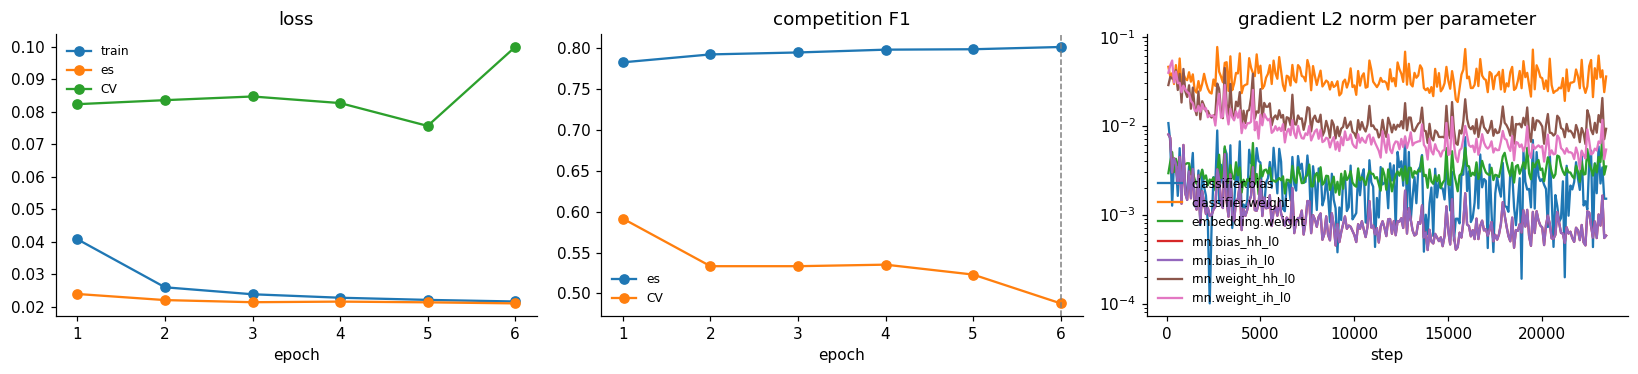

In [17]:
metrics = pd.read_csv(ARTIFACTS / CFG["run_name"] / "logs" / "metrics.csv")
per_epoch = metrics.groupby("epoch").last()  # last non-empty value of every column
epoch_axis = per_epoch.index + 1

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for col, label in [("train_loss_epoch", "train"), ("es_loss", "es"), ("cv_loss", "CV")]:
    axes[0].plot(epoch_axis, per_epoch[col], marker="o", label=label)
axes[0].set(title="loss", xlabel="epoch")
for col, label in [("es_f1", "es"), ("cv_f1", "CV")]:
    axes[1].plot(epoch_axis, per_epoch[col], marker="o", label=label)
axes[1].axvline(report["best_epoch"] + 1, color="grey", ls="--", lw=1)
axes[1].set(title="competition F1", xlabel="epoch")
for col in [c for c in metrics.columns if c.startswith("grad_2.0_norm/")]:
    series = metrics[["step", col]].dropna()
    axes[2].plot(series.step, series[col], label=col.split("/")[1])
axes[2].set(title="gradient L2 norm per parameter", xlabel="step", yscale="log")
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

Error analysis on CV: every text where the prediction differs from gold, after `hard_processing`.

In [18]:
rows = []
for text, gold, pred in zip(corpora["cv"].texts, corpora["cv"].gold, cv_pred):
    g, p = {hard_processing(x) for x in gold}, {hard_processing(x) for x in pred}
    if g != p:
        rows.append({"text": text[:100].replace("\n", " ⏎ "), "missed": sorted(g - p), "extra": sorted(p - g),
                     "correct": sorted(g & p)})
print(f"{len(rows)} of {len(cv_pred)} CV texts have an error")
pd.DataFrame(rows)

17 of 26 CV texts have an error


,text,missed,extra,correct
0,"Проспект Бандери стоїть, як і пів міста… довго ще?? ⏎ ⏎ Життя🫶Оболонь",[],[оболонь],[проспект бандери]
1,☢️Радіаційний фон (мкР/год) по Київщині станом на 9 год 28 серпня: ⏎ ⏎ Чорнобиль - 19 ⏎ Київ - 12 ⏎ Тетерів,"[баришівка, бориспіль, біла церква, миронівка, тетерів, фастів, яготин]",[],"[київ, київщині, чорнобиль]"
2,"Друзі. Останні дві ночі, і ще декілька наступних, ми з вами будемо відчувати певний дискомфорт у звʼ",[],"[оболонь, проспекту]",[проспекті івасюка]
3,Сьогодні з Києва до Хелма вперше вирушив новий міжнародний поїзд Укрзалізниці🚊 ⏎ ⏎ Як він курсуватиме👈,[хелма],[],[києва]
4,Подовження роботи закладів харчування ⏎ ⏎ Владою Києва прийнято рішення щодо подовження роботи закладів,[],"[києва, україні]",[києву]
5,"Нарешті офіційні новини, які можна розповідати. ⏎ ⏎ Звільнення на цьому тижні: ⏎ ⏎ - звільнення міністра",[],[україни],[]
6,ДТП біля заїзду в ТЦ Аркадія ⏎ ⏎ 📍Індустріальний міст,[тц аркадія],[тц аркадія 📍],[]
7,“Київський метрополітен” отримав ще 6 вагонів від варшавського метро ⏎ ⏎ 🇵🇱Столичний метрополітен у сер,[],[🇱],[]
8,В результате массированной атаки врага ночью в Фастовском и Бучанском районах возникли пожары и разр,"[бучанском, фастовском]",[],[]
9,😱 Жесть на Троєщині хлопця пирнули ножем на зупинці ⏎ ⏎ Нападника одразу ж затримали небайдужі. Свої ді,[],[київ],[троєщині]


**Baseline: CV 0.488 (95% CI 0.34–0.66), es 0.802, public LB 0.459.** CV and LB agree within the interval.

- **More training helps the train domain and hurts the test domain.** es F1 rises every epoch (0.78 → 0.80), so early
  stopping never fires and the checkpoint is epoch 6. CV F1 is best after epoch 1 (0.59) and falls to 0.49, and the CV
  loss jumps at epoch 6. The model fits Ukr-Synth sentences better and better and transfers worse to Telegram posts.
  The 26 CV texts alone can't prove this (the interval is ±0.16), but the LB points the same way: the first version of
  this baseline stopped at epoch 3 and scored LB 0.495 against 0.459 now. That version also had a smaller model and
  lr, so it is a hint, not proof. **For the team:** try fewer epochs or a lower lr, and confirm the choice on the LB,
  not only on es.
- **The optimization is healthy.** Train and es loss fall together, so there is no overfitting inside the train domain.
  Gradient norms are stable over 23k steps: no spikes (exploding) and no collapse to zero (vanishing) at the parameter
  level. The total norm stays far below the clipping threshold of 1.0, so clipping never acted. These per-parameter
  norms cannot show gradients vanishing *through time* inside BPTT; that is what GRU and LSTM cells address (point 3).
- **Precision is the weak side (0.40 against recall 0.63).** 40% of the CV texts without a location still get one.
  The error table shows four kinds of false positives:
  - **channel signatures:** `Оболонь` from `Життя🫶Оболонь`, `Київ` from `Хуйовий Київ | Надіслати новину` (filter, 7.4);
  - **countries:** `України`, `Україні`, which gold doesn't label (7.4);
  - **emoji and symbols** tagged as locations (`🇱`, `🕑`, `✔`, `,`). Ukr-Synth has no emoji, so they are all `<unk>`, and
    an `<unk>` next to a place name looks like part of it. A "must contain a letter" filter removes them (7.3);
  - **boundaries:** `ТЦ Аркадія 📍` instead of `ТЦ Аркадія`, `Дніпра` instead of `Героїв Дніпра`.
- **Misses** come from towns listed without context (`Фастів - 9`: 7 misses in the radiation post), unseen names
  (`Хелма`) and Russian forms (`Фастовском`, `Бучанском`) that the word vocabulary has never seen. BPE (notebook 05)
  and fastText (notebook 06) target exactly these.
- **Gold is not exhaustive.** In the train-schedule post the model finds `Боярка`, `Вишневе`, `Тарасівка`, which are
  real stations, but gold has only `Києвом` and `Васильковом`. Some false positives are annotation choices, and they
  cap the precision any model can reach.

## 4. First Kaggle submission (2.4)
The run goes into the results log. If it has no LB score yet, it is submitted, and the public score is written into
the log. Re-running the notebook does not submit again.

In [19]:
log = log_result(CFG, report, notes="baseline")
has_lb = pd.notna(log.set_index("run_name").loc[CFG["run_name"], "lb_public"])
if QUICK_RUN:
    print("quick run: not submitting")
elif not has_lb:
    submit(CFG, report, notes="baseline")
    log = read_log()
log

ivan-rnn1-word-random: public LB = 0.45892


,run_name,owner,point,description,cv_f1,cv_p,cv_r,es_f1,lb_public,notes
0,ivan-rnn1-word-random,ivan,2,"Vanilla RNN, 1 layer, unidirectional, word-level lowercase 50k vocab, random init, AdamW",0.487805,0.4,0.625,0.801731,0.45892,baseline


## 5. CV vs LB (2.5)
Every run in the results log that has a public score, from all three of us. If the CV ranking follows the LB, we can
trust CV for decisions between submissions. If es ranks runs better than CV does, the 26 CV texts are too few.
Spearman correlation needs at least 3 runs.

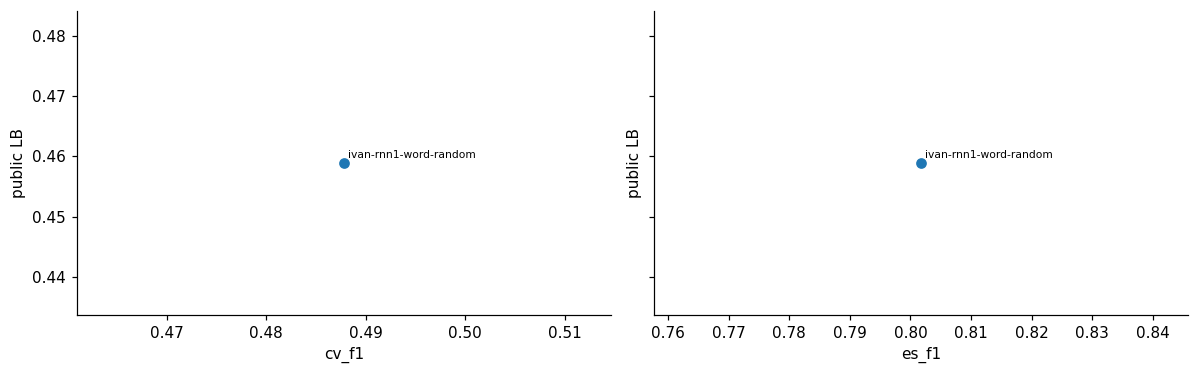

,run_name,owner,cv_f1,es_f1,lb_public
0,ivan-rnn1-word-random,ivan,0.487805,0.801731,0.45892


In [20]:
submitted = read_log().dropna(subset=["lb_public"])
if len(submitted):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
    for ax, col in zip(axes, ["cv_f1", "es_f1"]):
        ax.scatter(submitted[col], submitted.lb_public)
        for _, r in submitted.iterrows():
            ax.annotate(r.run_name, (r[col], r.lb_public), fontsize=7, xytext=(3, 3), textcoords="offset points")
        ax.set(xlabel=col, ylabel="public LB")
    plt.tight_layout()
    plt.show()
if len(submitted) >= 3:
    print("Spearman with public LB:", {col: round(submitted[col].corr(submitted.lb_public, method="spearman"), 3)
                                        for col in ("cv_f1", "es_f1")})
submitted[["run_name", "owner", "cv_f1", "es_f1", "lb_public"]].sort_values("lb_public", ascending=False)

_Written on Nov 11, once at least 5 runs from the team have a public score._